In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

import warnings
warnings.filterwarnings("ignore")

sns.set_theme(style="whitegrid")

print("Libraries imported successfully!")

Libraries imported successfully!


In [4]:
df = pd.read_csv("train_u6lujuX_CVtuZ9i .csv")


In [5]:
df.shape

(614, 13)

In [6]:
df.head()

,Loan_ID,Gender,Married,Dependents,Education,Self_Employed,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History,Property_Area,Loan_Status
0,LP001002,Male,No,0,Graduate,No,5849,0.0,NaN,360.0,1.0,Urban,Y
1,LP001003,Male,Yes,1,Graduate,No,4583,1508.0,128.0,360.0,1.0,Rural,N
2,LP001005,Male,Yes,0,Graduate,Yes,3000,0.0,66.0,360.0,1.0,Urban,Y
3,LP001006,Male,Yes,0,Not Graduate,No,2583,2358.0,120.0,360.0,1.0,Urban,Y
4,LP001008,Male,No,0,Graduate,No,6000,0.0,141.0,360.0,1.0,Urban,Y


In [7]:
df.describe()

,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History
count,614.000000,614.000000,592.000000,600.00000,564.000000
mean,5403.459283,1621.245798,146.412162,342.00000,0.842199
std,6109.041673,2926.248369,85.587325,65.12041,0.364878
min,150.000000,0.000000,9.000000,12.00000,0.000000
25%,2877.500000,0.000000,100.000000,360.00000,1.000000
50%,3812.500000,1188.500000,128.000000,360.00000,1.000000
75%,5795.000000,2297.250000,168.000000,360.00000,1.000000
max,81000.000000,41667.000000,700.000000,480.00000,1.000000


In [8]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 614 entries, 0 to 613
Data columns (total 13 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Loan_ID            614 non-null    object 
 1   Gender             601 non-null    object 
 2   Married            611 non-null    object 
 3   Dependents         599 non-null    object 
 4   Education          614 non-null    object 
 5   Self_Employed      582 non-null    object 
 6   ApplicantIncome    614 non-null    int64  
 7   CoapplicantIncome  614 non-null    float64
 8   LoanAmount         592 non-null    float64
 9   Loan_Amount_Term   600 non-null    float64
 10  Credit_History     564 non-null    float64
 11  Property_Area      614 non-null    object 
 12  Loan_Status        614 non-null    object 
dtypes: float64(4), int64(1), object(8)
memory usage: 62.5+ KB


In [12]:
df.columns.tolist()

['Loan_ID',
 'Gender',
 'Married',
 'Dependents',
 'Education',
 'Self_Employed',
 'ApplicantIncome',
 'CoapplicantIncome',
 'LoanAmount',
 'Loan_Amount_Term',
 'Credit_History',
 'Property_Area',
 'Loan_Status']

In [13]:
df.isnull().sum()

Loan_ID               0
Gender               13
Married               3
Dependents           15
Education             0
Self_Employed        32
ApplicantIncome       0
CoapplicantIncome     0
LoanAmount           22
Loan_Amount_Term     14
Credit_History       50
Property_Area         0
Loan_Status           0
dtype: int64

In [14]:
df.duplicated().sum()

np.int64(0)

In [15]:
df = df.drop(columns=["Loan_ID"])

print("Dataset shape:", df.shape)
print(df.head())

Dataset shape: (614, 12)
  Gender Married Dependents     Education Self_Employed  ApplicantIncome  \
0   Male      No          0      Graduate            No             5849   
1   Male     Yes          1      Graduate            No             4583   
2   Male     Yes          0      Graduate           Yes             3000   
3   Male     Yes          0  Not Graduate            No             2583   
4   Male      No          0      Graduate            No             6000   

   CoapplicantIncome  LoanAmount  Loan_Amount_Term  Credit_History  \
0                0.0         NaN             360.0             1.0   
1             1508.0       128.0             360.0             1.0   
2                0.0        66.0             360.0             1.0   
3             2358.0       120.0             360.0             1.0   
4                0.0       141.0             360.0             1.0   

  Property_Area Loan_Status  
0         Urban           Y  
1         Rural           N  
2      

In [16]:
print(df["Loan_Status"].value_counts())

Loan_Status
Y    422
N    192
Name: count, dtype: int64


In [17]:
X = df.drop(columns=["Loan_Status"])
y = df["Loan_Status"]

print("Features shape:", X.shape)
print("Target shape:", y.shape)

Features shape: (614, 11)
Target shape: (614,)


In [18]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)
print("Training target:", y_train.shape)
print("Testing target:", y_test.shape)

Training features: (491, 11)
Testing features: (123, 11)
Training target: (491,)
Testing target: (123,)


In [19]:
# Identify numerical columns
numerical_features = X_train.select_dtypes(include=["number"]).columns.tolist()

# Identify categorical columns
categorical_features = X_train.select_dtypes(exclude=["number"]).columns.tolist()

print("Numerical features:", numerical_features)
print("\nCategorical features:", categorical_features)

Numerical features: ['ApplicantIncome', 'CoapplicantIncome', 'LoanAmount', 'Loan_Amount_Term', 'Credit_History']

Categorical features: ['Gender', 'Married', 'Dependents', 'Education', 'Self_Employed', 'Property_Area']


In [20]:
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer

# Preprocessing for numerical columns
numerical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median"))
])

# Preprocessing for categorical columns
categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

# Combine both preprocessing pipelines
preprocessor = ColumnTransformer(transformers=[
    ("numerical", numerical_transformer, numerical_features),
    ("categorical", categorical_transformer, categorical_features)
])

print("Preprocessing pipeline created successfully!")

Preprocessing pipeline created successfully!


In [23]:
print("Missing values in X_train:")
print(X_train.isnull().sum())

print("\nTotal missing values in X_train:", X_train.isnull().sum().sum())

Missing values in X_train:
Gender               11
Married               3
Dependents            8
Education             0
Self_Employed        27
ApplicantIncome       0
CoapplicantIncome     0
LoanAmount           20
Loan_Amount_Term     12
Credit_History       43
Property_Area         0
dtype: int64

Total missing values in X_train: 124


In [27]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import Pipeline

# Create the machine learning pipeline
model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", RandomForestClassifier(
        n_estimators=200,
        random_state=42,
        class_weight="balanced"
    ))
])

# Train the model
model.fit(X_train, y_train)

print("Model training completed successfully!")

Model training completed successfully!


In [28]:
import numpy as np

# Transform the training and testing data
X_train_processed = model.named_steps["preprocessor"].transform(X_train)
X_test_processed = model.named_steps["preprocessor"].transform(X_test)

# Check for missing values
print("Missing values after preprocessing:")

print("Training data:", np.isnan(X_train_processed).sum())
print("Testing data:", np.isnan(X_test_processed).sum())

Missing values after preprocessing:
Training data: 0
Testing data: 0


In [32]:
# Predict loan status for the test dataset
y_pred = model.predict(X_test)

print("Actual Loan Status:")
print(y_test.head(10).values)

print("\nPredicted Loan Status:")
print(y_pred[:10])

Actual Loan Status:
['N' 'Y' 'Y' 'Y' 'Y' 'N' 'Y' 'Y' 'Y' 'Y']

Predicted Loan Status:
['N' 'Y' 'Y' 'Y' 'Y' 'Y' 'Y' 'Y' 'N' 'Y']


In [33]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report
)

# Calculate evaluation metrics
accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred, pos_label="Y", zero_division=0)
recall = recall_score(y_test, y_pred, pos_label="Y", zero_division=0)
f1 = f1_score(y_test, y_pred, pos_label="Y", zero_division=0)

# Display results
print("Model Evaluation Results")
print("-" * 30)
print(f"Accuracy:  {accuracy:.4f} ({accuracy * 100:.2f}%)")
print(f"Precision: {precision:.4f}")
print(f"Recall:    {recall:.4f}")
print(f"F1-score:  {f1:.4f}")

print("\nClassification Report:")
print(classification_report(y_test, y_pred, zero_division=0))

Model Evaluation Results
------------------------------
Accuracy:  0.8211 (82.11%)
Precision: 0.8387
Recall:    0.9176
F1-score:  0.8764

Classification Report:
              precision    recall  f1-score   support

           N       0.77      0.61      0.68        38
           Y       0.84      0.92      0.88        85

    accuracy                           0.82       123
   macro avg       0.80      0.76      0.78       123
weighted avg       0.82      0.82      0.81       123



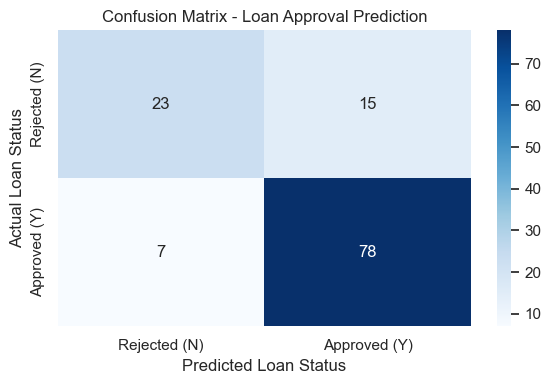

In [34]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

# Create confusion matrix
cm = confusion_matrix(y_test, y_pred, labels=["N", "Y"])

# Visualize confusion matrix
plt.figure(figsize=(6, 4))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Rejected (N)", "Approved (Y)"],
    yticklabels=["Rejected (N)", "Approved (Y)"]
)

plt.title("Confusion Matrix - Loan Approval Prediction")
plt.xlabel("Predicted Loan Status")
plt.ylabel("Actual Loan Status")
plt.tight_layout()
plt.show()

In [35]:
import pandas as pd

# Create a results DataFrame
results = pd.DataFrame({
    "Actual Loan Status": y_test.values,
    "Predicted Loan Status": y_pred
})

# Convert status codes into readable labels
results["Actual Loan Status"] = results["Actual Loan Status"].map({
    "Y": "Approved",
    "N": "Rejected"
})

results["Predicted Loan Status"] = results["Predicted Loan Status"].map({
    "Y": "Approved",
    "N": "Rejected"
})

# Check whether each prediction is correct
results["Prediction Correct"] = (
    results["Actual Loan Status"] == results["Predicted Loan Status"]
)

# Display the first 10 results
print(results.head(10).to_string(index=False))

Actual Loan Status Predicted Loan Status  Prediction Correct
          Rejected              Rejected                True
          Approved              Approved                True
          Approved              Approved                True
          Approved              Approved                True
          Approved              Approved                True
          Rejected              Approved               False
          Approved              Approved                True
          Approved              Approved                True
          Approved              Rejected               False
          Approved              Approved                True


In [36]:
correct_predictions = results["Prediction Correct"].sum()
total_predictions = len(results)

print("Total test applications:", total_predictions)
print("Correct predictions:", correct_predictions)
print("Incorrect predictions:", total_predictions - correct_predictions)
print(f"Accuracy: {correct_predictions / total_predictions * 100:.2f}%")

Total test applications: 123
Correct predictions: 101
Incorrect predictions: 22
Accuracy: 82.11%


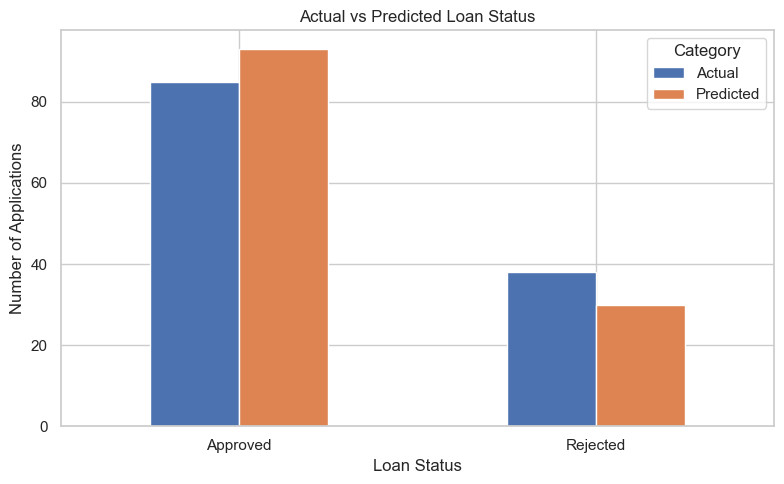

In [37]:
import pandas as pd
import matplotlib.pyplot as plt

comparison = pd.DataFrame({
    "Actual": y_test.map({"Y": "Approved", "N": "Rejected"}).value_counts(),
    "Predicted": pd.Series(y_pred).map({
        "Y": "Approved",
        "N": "Rejected"
    }).value_counts()
}).fillna(0)

comparison.plot(kind="bar", figsize=(8, 5))

plt.title("Actual vs Predicted Loan Status")
plt.xlabel("Loan Status")
plt.ylabel("Number of Applications")
plt.xticks(rotation=0)
plt.legend(title="Category")
plt.tight_layout()
plt.show()

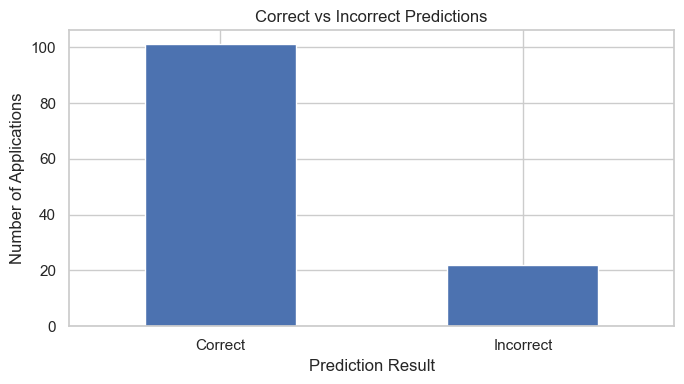

In [38]:
prediction_counts = results["Prediction Correct"].value_counts()
prediction_counts.index = prediction_counts.index.map({
    True: "Correct",
    False: "Incorrect"
})

prediction_counts = prediction_counts.reindex(
    ["Correct", "Incorrect"], fill_value=0
)

prediction_counts.plot(
    kind="bar",
    figsize=(7, 4)
)

plt.title("Correct vs Incorrect Predictions")
plt.xlabel("Prediction Result")
plt.ylabel("Number of Applications")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [39]:
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline

# Create Logistic Regression pipeline
lr_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(
        max_iter=1000,
        class_weight="balanced",
        random_state=42
    ))
])

# Train the model
lr_model.fit(X_train, y_train)

print("Logistic Regression training completed!")

Logistic Regression training completed!


In [40]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)
import pandas as pd

# Generate predictions
rf_predictions = model.predict(X_test)
lr_predictions = lr_model.predict(X_test)

# Compare the models
comparison = pd.DataFrame({
    "Model": ["Random Forest", "Logistic Regression"],
    "Accuracy": [
        accuracy_score(y_test, rf_predictions),
        accuracy_score(y_test, lr_predictions)
    ],
    "Precision": [
        precision_score(y_test, rf_predictions, pos_label="Y", zero_division=0),
        precision_score(y_test, lr_predictions, pos_label="Y", zero_division=0)
    ],
    "Recall": [
        recall_score(y_test, rf_predictions, pos_label="Y", zero_division=0),
        recall_score(y_test, lr_predictions, pos_label="Y", zero_division=0)
    ],
    "F1-Score": [
        f1_score(y_test, rf_predictions, pos_label="Y", zero_division=0),
        f1_score(y_test, lr_predictions, pos_label="Y", zero_division=0)
    ]
})

print(comparison.round(4).to_string(index=False))

              Model  Accuracy  Precision  Recall  F1-Score
      Random Forest    0.8211     0.8387  0.9176    0.8764
Logistic Regression    0.8293     0.8721  0.8824    0.8772


In [41]:
import joblib

# Save the complete trained pipeline
joblib.dump(lr_model, "loan_approval_model.pkl")

print("Model saved successfully!")

Model saved successfully!


In [42]:
import os

if os.path.exists("loan_approval_model.pkl"):
    print("Model file exists.")
    print("File size:", round(
        os.path.getsize("loan_approval_model.pkl") / 1024, 2
    ), "KB")
else:
    print("Model file not found.")

Model file exists.
File size: 5.26 KB
